# Дистилляция диффузионных моделей

CIFAR-10 32×32, `google/ddpm-cifar10-32`, Progressive Distillation 64 → 32.
Ученик заменяет два детерминированных DDIM-перехода учителя одним.


## 1. Параметры эксперимента

Вычисления выполняются на MPS в FP32. Пилот содержит 100 обновлений; оценка качества — по 10 000 генераций для каждой модели.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from diffusion_distill import project

ROOT = Path(".")
DEVICE = "mps"
SAMPLES = 10_000
UPDATES = 100
TIME_LIMIT = 1200
BATCH_SIZE = 32
CHECKPOINT = ROOT / "artifacts/local/pilot/checkpoint.pt"


## 2. Данные

Обучающая подвыборка содержит 2048 изображений CIFAR-10 train. Начальные шумы заданы seed 20261104 и сохраняются для сопоставимых прогонов. Ревизия предобученных весов закреплена в конфигурации.


In [2]:
prepared = project.prepare(ROOT, count=SAMPLES)
{
    "model": prepared["model"]["model_id"],
    "revision": prepared["model"]["revision"],
    "train_images": prepared["dataset"]["training_subset_count"],
    "samples": prepared["noise"]["count"],
    "seed": prepared["noise"]["seed"],
}


/Users/b-karamov/Desktop/edu/gen-cv/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model: google/ddpm-cifar10-32, revision: 267b167dc01f0e4e61923ea244e8b988f84deb80


Dataset: CIFAR-10 train


{'model': 'google/ddpm-cifar10-32',
 'revision': '267b167dc01f0e4e61923ea244e8b988f84deb80',
 'train_images': 2048,
 'samples': 10000,
 'seed': 20261104}

## 3. Учитель DDIM-64

Веса учителя заморожены. Сэмплер использует eta=0 и отключённый промежуточный clipping. Сетка содержит первые 16 фиксированных шумов.


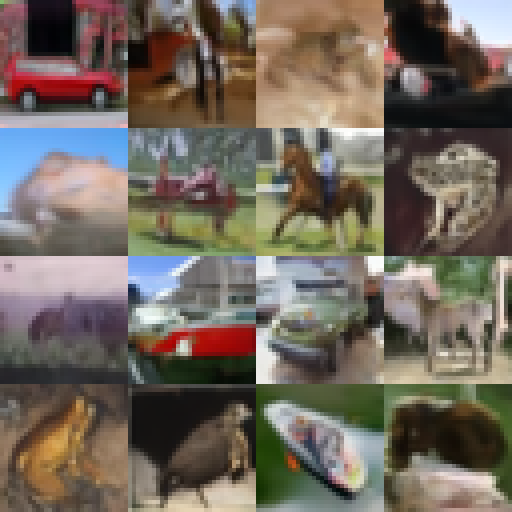

In [3]:
teacher_preview = project.preview(ROOT, device=DEVICE)
display(Image(filename=str(ROOT / "artifacts/local/teacher/grid.png")))


## 4. Обучение 64 → 32

Ученик инициализируется весами учителя. Аналитическая цель одного перехода получается из двух шагов учителя. Потеря — средний epsilon MSE; оптимизатор — AdamW, lr=1e-5, batch=2. EMA имеет коэффициент 0.95.


In [4]:
pilot_result = project.pilot(
    ROOT,
    device=DEVICE,
    max_steps=UPDATES,
    max_seconds=TIME_LIMIT,
)
{
    "updates": pilot_result["completed_steps"],
    "training_seconds": round(pilot_result["training_seconds"], 3),
}


{'updates': 100, 'training_seconds': 35.807}

## 5. Динамика обучения

Кривые содержат epsilon MSE и норму градиента до clipping на случайных обучающих batch


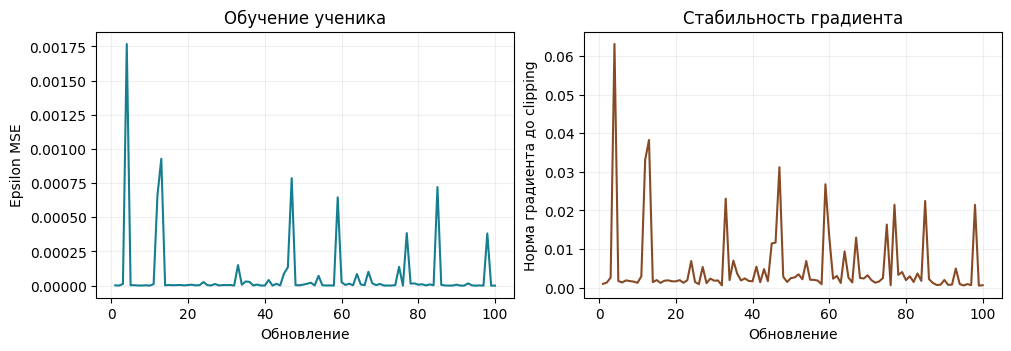

In [5]:
history = pilot_result["history"]
steps = [row["step"] for row in history]
losses = [row["loss"] for row in history]
grad_norms = [row["grad_norm"] for row in history]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
axes[0].plot(steps, losses, color="#157e91")
axes[0].set(xlabel="Обновление", ylabel="Epsilon MSE", title="Обучение ученика")
axes[1].plot(steps, grad_norms, color="#874a24")
axes[1].set(xlabel="Обновление", ylabel="Норма градиента до clipping", title="Стабильность градиента")
for axis in axes:
    axis.grid(alpha=.2)
plt.show()


## 6. EMA-ученик DDIM-32

EMA-веса относятся к checkpoint шага 100. Начальные шумы совпадают с сеткой учителя; одна траектория содержит 32 вызова U-Net.


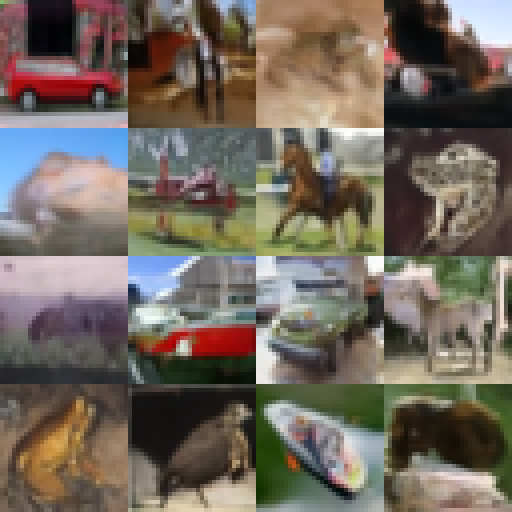

In [6]:
student_preview = project.preview(ROOT, device=DEVICE, checkpoint=CHECKPOINT)
display(Image(filename=str(ROOT / "artifacts/local/student_ema/grid.png")))


## 7. Оценка учителя

Clean-FID в режиме clean сопоставляет 10 000 генераций со статистиками CIFAR-10 train50k. Время измеряется отдельно для batch=1 и 32: 5 прогревов и 3 серии по 10 измерений с синхронизацией MPS. DDPM-1000 служит отдельным визуальным контролем.


FID: 16.361
NFE: 64


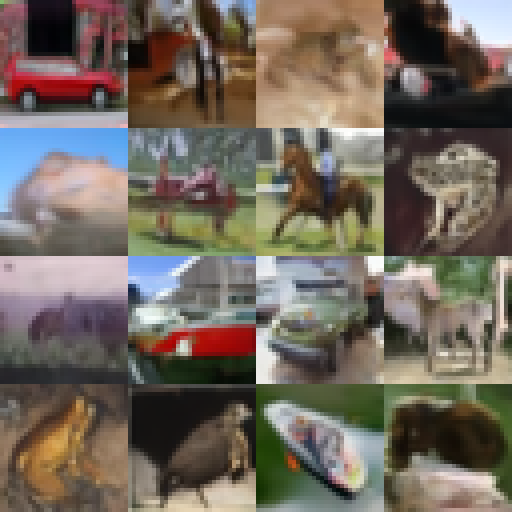

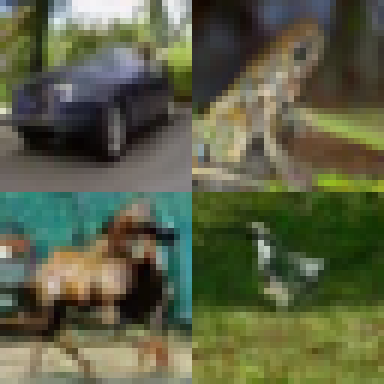

In [7]:
teacher_metrics = project.baseline(ROOT, device=DEVICE, batch_size=BATCH_SIZE)
print(f"FID: {teacher_metrics['fid']['value']:.3f}")
print(f"NFE: {teacher_metrics['generation']['nfe_per_image']}")
display(Image(filename=str(ROOT / "artifacts/baseline/grid.png")))
display(Image(filename=str(ROOT / "artifacts/baseline/ddpm_control.png")))


## 8. Оценка ученика

Используются те же 10 000 начальных шумов и тот же протокол FID. Скорость ученика и учителя измеряется на одном устройстве


Student timing


Teacher timing


Student FID


FID: 16.214
NFE: 32
B=1: 1.169 → 0.584 с; 2.00×
B=32: 18.635 → 9.453 с; 1.97×


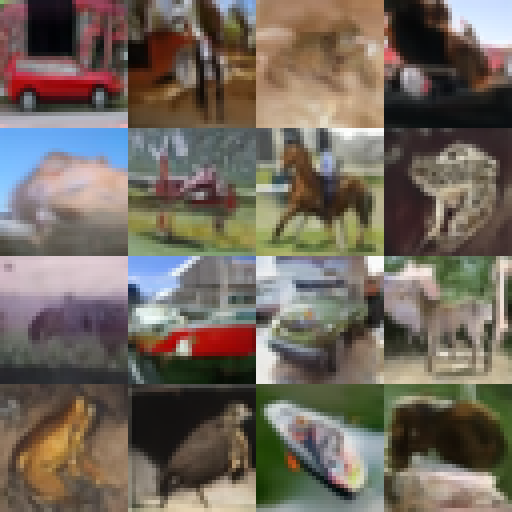

In [8]:
student_metrics = project.evaluate_student(
    ROOT,
    device=DEVICE,
    batch_size=BATCH_SIZE,
    checkpoint=CHECKPOINT,
)
print(f"FID: {student_metrics['fid']['value']:.3f}")
print(f"NFE: {student_metrics['generation']['nfe_per_image']}")
for row in student_metrics["speedup"]:
    print(f"B={row['batch_size']}: {row['teacher_batch_seconds']:.3f} → {row['student_batch_seconds']:.3f} с; {row['speedup']:.2f}×")
display(Image(filename=str(ROOT / "artifacts/student_baseline/grid.png")))


## Результаты

На сохранённом прогоне FID учителя равен 16.361, ученика — 16.214; NFE уменьшен с 64 до 32. Измеренное отношение времени составляет около 2×.

[Метрики CSV](results/metrics.csv) · [Протокол и измерения](results/metrics.json)

План экспериментов этапа 2 приведён в разделе 6 отчёта.
